In [5]:

import numpy as np
import matplotlib.pyplot as plt

def my_stft(x, L, overlap, window):
    x = np.asarray(x, dtype=float)
    R = L - overlap
    w = np.asarray(window, dtype=float)

    if L <= 0 or overlap < 0 or overlap >= L:
        raise ValueError("L hoặc overlap không hợp lệ")
    if len(w) != L:
        raise ValueError("Độ dài cửa sổ phải bằng L")

    n_frames = max(1, int(np.ceil(max(0, len(x) - L) / R)) + 1)
    total_length = (n_frames - 1) * R + L
    x_pad = np.pad(x, (0, max(0, total_length - len(x))))

    X = np.zeros((L, n_frames), dtype=complex)

    for m in range(n_frames):
        start = m * R
        frame = x_pad[start:start + L]
        X[:, m] = np.fft.fft(frame * w, n=L)

    return X


def my_istft(X, L, overlap, window):
    X = np.asarray(X)
    w = np.asarray(window, dtype=float)
    R = L - overlap

    if L <= 0 or overlap < 0 or overlap >= L:
        raise ValueError("L hoặc overlap không hợp lệ")
    if len(w) != L or X.shape[0] != L:
        raise ValueError("Kích thước cửa sổ hoặc STFT không hợp lệ")

    n_frames = X.shape[1]
    output_length = (n_frames - 1) * R + L

    x_sum = np.zeros(output_length)
    w_sum = np.zeros(output_length)

    for m in range(n_frames):
        start = m * R
        frame = np.fft.ifft(X[:, m]).real

        x_sum[start:start + L] += frame * w
        w_sum[start:start + L] += w**2

    x_rec = np.zeros(output_length)
    valid = w_sum > 1e-12
    x_rec[valid] = x_sum[valid] / w_sum[valid]

    return x_rec


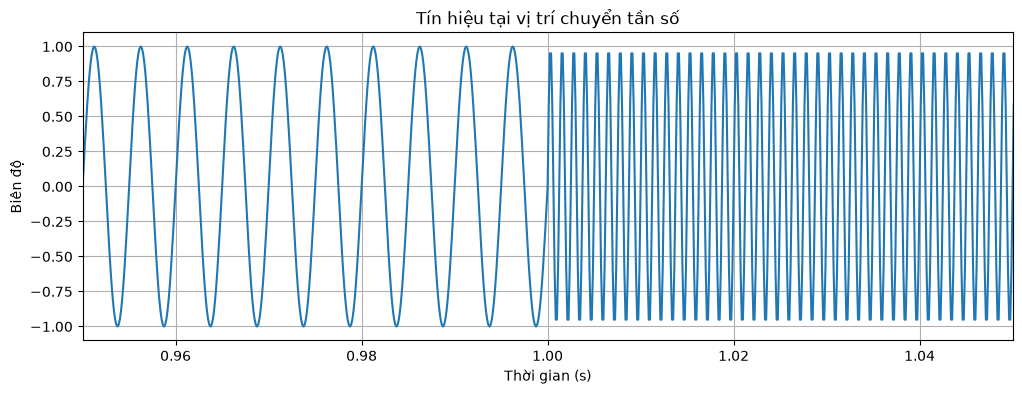

In [6]:

fs = 8000
L = 256
overlap = 128
R = L - overlap

t = np.arange(2 * fs) / fs

x = np.zeros(len(t))
x[t < 1] = np.sin(2 * np.pi * 200 * t[t < 1])
x[t >= 1] = np.sin(2 * np.pi * 800 * t[t >= 1])

plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.xlim(0.95, 1.05)
plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ")
plt.title("Tín hiệu tại vị trí chuyển tần số")
plt.grid(True)
plt.show()


In [7]:

windows = {
    "Rectangular": np.ones(L),
    "Hamming": np.hamming(L),
    "Hann": np.hanning(L)
}

results = {}
errors = {}

for name, w in windows.items():
    X = my_stft(x, L, overlap, w)
    x_rec = my_istft(X, L, overlap, w)

    # Cắt về đúng độ dài tín hiệu ban đầu
    x_rec = x_rec[:len(x)]

    # Sai số tái tạo tương đối
    E = np.linalg.norm(x - x_rec) / np.linalg.norm(x)

    results[name] = (X, x_rec)
    errors[name] = E

    print(f"{name:12s}: E = {E:.3e}")

print("Số mẫu tín hiệu:", len(x))
print("Hop size:", R)


Rectangular : E = 1.727e-16
Hamming     : E = 2.073e-16
Hann        : E = 6.572e-03
Số mẫu tín hiệu: 16000
Hop size: 128


Rectangular : E = 1.96903205e-16
Hamming     : E = 2.19624152e-16
Hann        : E = 6.57163890e-03


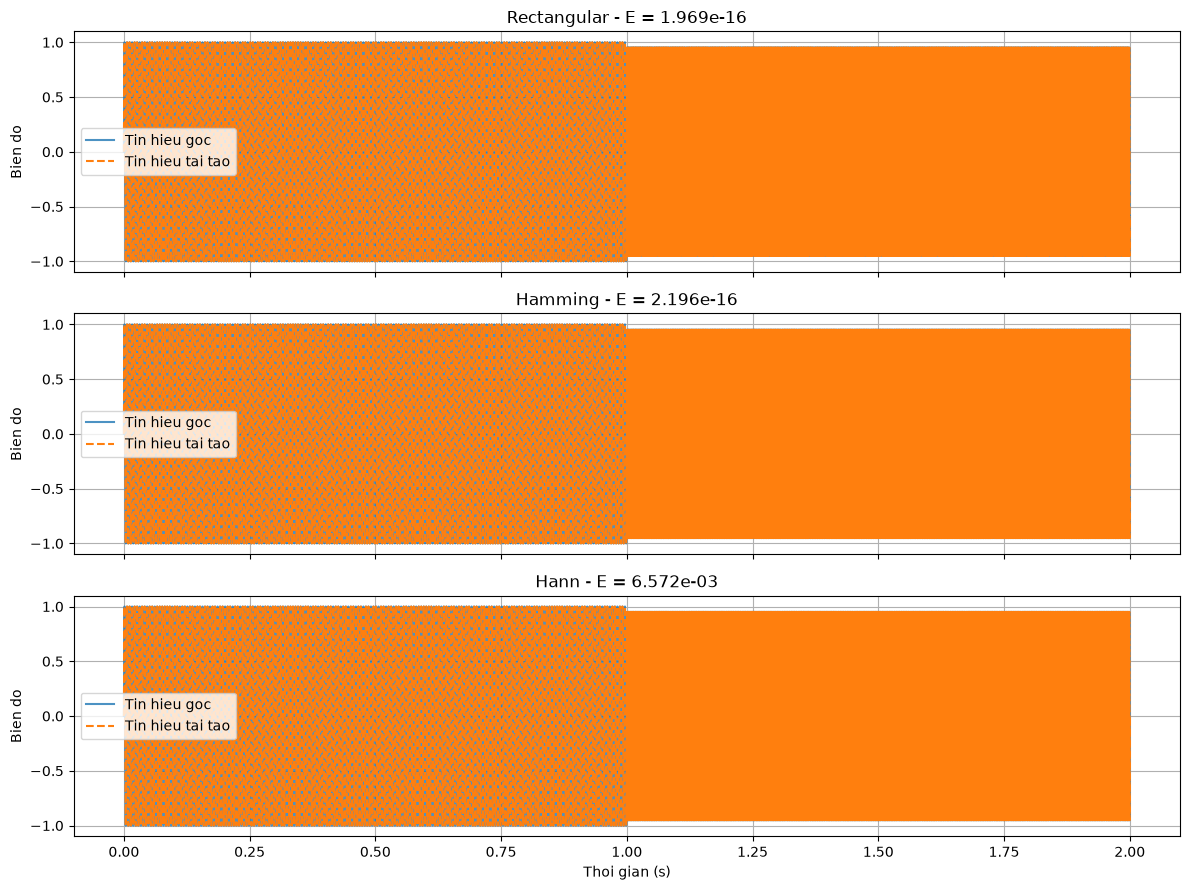

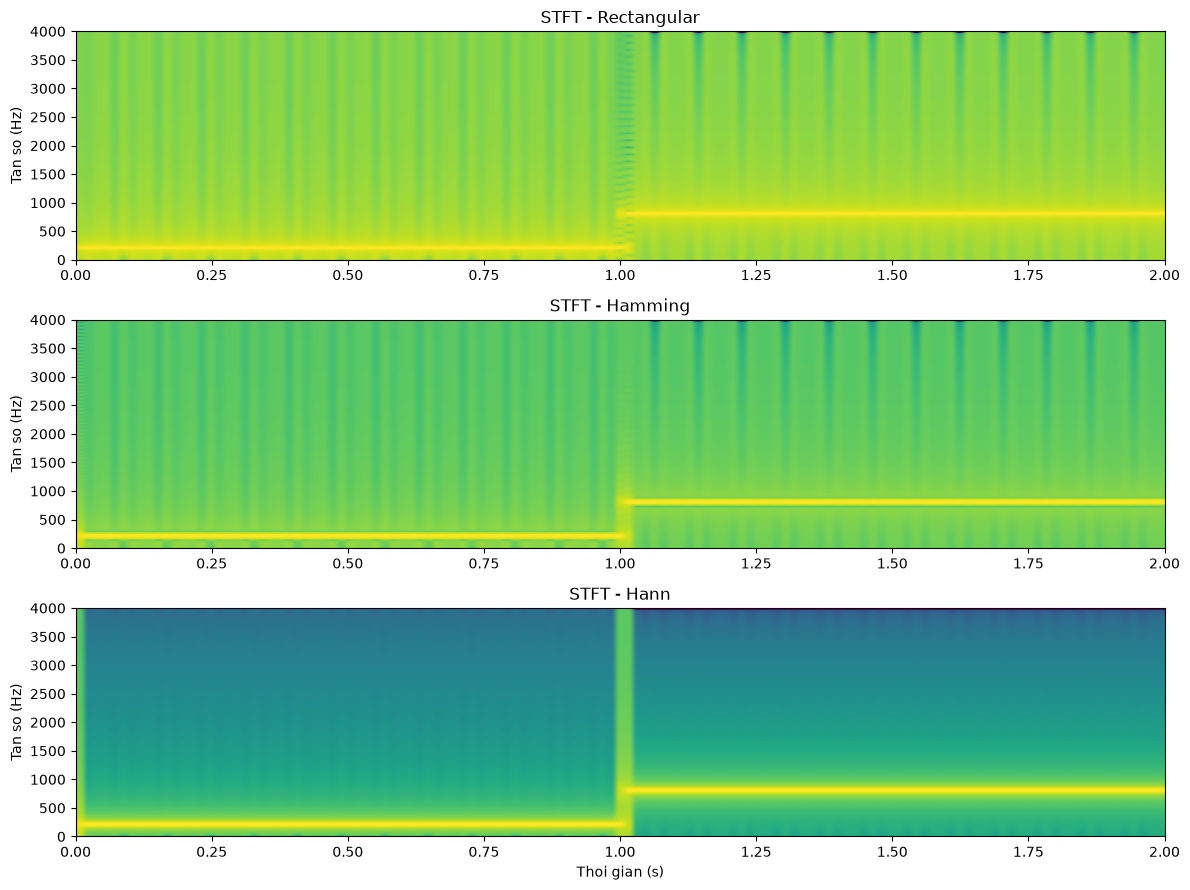

In [1]:
import numpy as np
import matplotlib.pyplot as plt


# Hàm STFT
def my_stft(x, L, overlap, window):
    R = L - overlap
    pad_left = L // 2

    # Đệm tín hiệu ở đầu và cuối
    x_pad = np.pad(x, (pad_left, 0))

    remainder = (len(x_pad) - L) % R
    if remainder != 0:
        x_pad = np.pad(x_pad, (0, R - remainder))

    # Chia tín hiệu thành các khung và tính FFT
    frames = []
    for start in range(0, len(x_pad) - L + 1, R):
        frame = x_pad[start:start + L] * window
        frames.append(np.fft.rfft(frame))

    return np.array(frames), pad_left


# Hàm ISTFT sử dụng WOLA
def my_istft(X, L, overlap, window, original_length, pad_left):
    R = L - overlap
    output_length = (X.shape[0] - 1) * R + L

    y = np.zeros(output_length)
    window_energy = np.zeros(output_length)

    for m in range(X.shape[0]):
        start = m * R
        frame = np.fft.irfft(X[m], n=L)

        y[start:start + L] += frame * window
        window_energy[start:start + L] += window ** 2

    # Chuẩn hóa theo tổng bình phương cửa sổ
    valid = window_energy > 1e-12
    y[valid] /= window_energy[valid]

    # Loại bỏ phần đệm, giữ lại tín hiệu ban đầu
    return y[pad_left:pad_left + original_length]


# Tạo tín hiệu kiểm tra
fs = 8000
t = np.arange(2 * fs) / fs

x = np.zeros_like(t)
x[t < 1] = np.sin(2 * np.pi * 200 * t[t < 1])
x[t >= 1] = np.sin(2 * np.pi * 800 * t[t >= 1])

# Tham số STFT
L = 256
overlap = 128

windows = {
    "Rectangular": np.ones(L),
    "Hamming": np.hamming(L),
    "Hann": np.hanning(L)
}

results = {}

# Phân tích, tái tạo và tính sai số
for name, window in windows.items():
    X, pad_left = my_stft(x, L, overlap, window)
    x_rec = my_istft(X, L, overlap, window, len(x), pad_left)

    E = np.linalg.norm(x - x_rec) / np.linalg.norm(x)

    results[name] = {
        "X": X,
        "x_rec": x_rec,
        "E": E
    }

    print(f"{name:12s}: E = {E:.8e}")

# Vẽ tín hiệu gốc và tín hiệu tái tạo
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (name, result) in zip(axes, results.items()):
    ax.plot(t, x, label="Tin hieu goc", alpha=0.8)
    ax.plot(t, result["x_rec"], "--", label="Tin hieu tai tao")
    ax.set_title(f"{name} - E = {result['E']:.3e}")
    ax.set_ylabel("Bien do")
    ax.grid(True)
    ax.legend()

axes[-1].set_xlabel("Thoi gian (s)")
plt.tight_layout()
plt.show()

# Vẽ phổ STFT của từng cửa sổ
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

for ax, (name, result) in zip(axes, results.items()):
    S_db = 20 * np.log10(np.abs(result["X"]).T + 1e-10)
    ax.imshow(
        S_db,
        origin="lower",
        aspect="auto",
        extent=[0, 2, 0, fs / 2],
        cmap="viridis"
    )
    ax.set_title(f"STFT - {name}")
    ax.set_ylabel("Tan so (Hz)")

axes[-1].set_xlabel("Thoi gian (s)")
plt.tight_layout()
plt.show()